# 🌿 ResNet-18 — Transfer Learning (bản gọn, train nhanh)

**Dữ liệu:** [PlantVillage – Leaf-Grouped Split (No Leakage)](https://www.kaggle.com/datasets/duydangkaggle/plantvillage-leaf-grouped-split)
— chia theo **từng chiếc lá**, valid/test **chỉ ảnh thật**.

**Vì sao ResNet-18 thay vì ResNet-50?** Cùng ý tưởng (khối dư + đường tắt), nhưng nhỏ hơn ~2,3 lần
(11 triệu so với 25 triệu tham số) → train nhanh hơn ~2–3 lần trên T4, độ chính xác trên PlantVillage gần như ngang.

### Chạy trên Google Colab
1. **Runtime → Change runtime type → T4 GPU → Save.**
2. **Runtime → Run all.** Ô đầu tiên hỏi quyền **Google Drive** → cho phép.
3. Kết quả lưu ở `MyDrive/plant-disease-ml/resnet18_runs/` → không mất khi Colab ngắt.

## 1. Chuẩn bị: thư viện, dữ liệu, GPU

In [ ]:
import os, sys, json, time, copy
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from sklearn.metrics import f1_score, confusion_matrix

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")                       # lưu kết quả lên Drive
    OUT_DIR = Path("/content/drive/MyDrive/plant-disease-ml/resnet18_runs")
    import kagglehub                                    # tải dữ liệu công khai (~2,3 GB, vài phút)
    DATA_DIR = Path(kagglehub.dataset_download("duydangkaggle/plantvillage-leaf-grouped-split")) / "data_v2"
else:                                                   # máy cá nhân
    DATA_DIR = Path(os.environ.get("DATA_DIR", "../data_v2_aug"))
    OUT_DIR = Path(os.environ.get("OUT_DIR", "../models"))
OUT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dữ liệu:", DATA_DIR, "| Thiết bị:", device)

Mounted at /content/drive
Using Colab cache for faster access to the 'plantvillage-leaf-grouped-split' dataset.
Dữ liệu: /kaggle/input/plantvillage-leaf-grouped-split/data_v2 | Thiết bị: cuda


## 2. Cấu hình — mọi "núm vặn" nằm ở đây

Muốn thử cải tiến → đổi **một** dòng, chạy lại, ghi kết quả.

In [ ]:
MODEL_NAME = "resnet18"
RUN_NAME = f"{MODEL_NAME}_duy"
IMAGE_SIZE = 224        # backend cũng resize về 224 → phải giống nhau
BATCH_SIZE = 128        # ResNet-18 nhẹ → batch lớn hơn, mỗi epoch ít bước hơn
EPOCHS = 5              # model đã học ImageNet → vài epoch là đủ
LR = 1e-3
NUM_WORKERS = os.cpu_count() or 2   # số tiến trình CPU đọc ảnh song song
torch.manual_seed(42)

## 3. Dữ liệu

* **Train:** resize 224 + **lật ngẫu nhiên** (ngang/dọc). Lật ảnh gần như không tốn CPU,
  còn xoay/chỉnh màu bằng PIL rất chậm trên 2 lõi CPU của Colab → GPU phải ngồi chờ. Bỏ đi cho nhanh.
* **Valid/Test:** chỉ resize 224 + chuẩn hóa — **giống hệt backend**, để model không "lạ" ảnh thật.

In [ ]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # chuẩn hóa giống lúc ResNet học ImageNet

train_tf = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_ds = datasets.ImageFolder(DATA_DIR / "train", train_tf)
valid_ds = datasets.ImageFolder(DATA_DIR / "valid", eval_tf)
CLASSES = train_ds.classes
NUM_CLASSES = len(CLASSES)
assert valid_ds.classes == CLASSES

train_loader = DataLoader(train_ds, BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
valid_loader = DataLoader(valid_ds, BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
print(f"{NUM_CLASSES} lớp | train {len(train_ds):,} ảnh | valid {len(valid_ds):,} ảnh")

38 lớp | train 81,146 ảnh | valid 8,147 ảnh


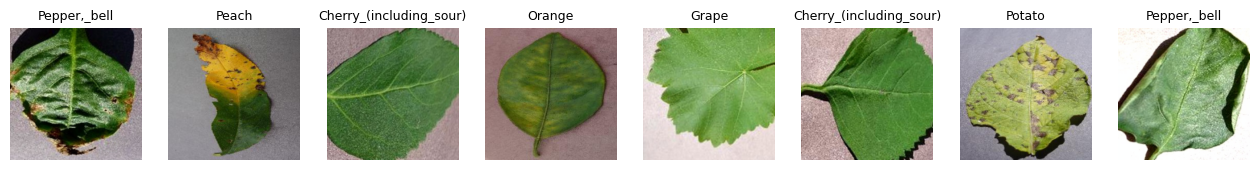

In [ ]:
def show(t):   # đảo chuẩn hóa để vẽ ảnh
    return np.clip(t.permute(1, 2, 0).numpy() * STD + MEAN, 0, 1)

imgs, ys = next(iter(DataLoader(train_ds, 8, shuffle=True)))
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for ax, im, y in zip(axes, imgs, ys):
    ax.imshow(show(im)); ax.set_title(CLASSES[y].split("___")[0], fontsize=9); ax.axis("off")
plt.show()

## 4. Model: ResNet-18 đã học ImageNet, thay lớp cuối 1.000 → 38 lớp

In [ ]:
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)    # 512 → 38
model = model.to(device)
print(f"Số tham số: {sum(p.numel() for p in model.parameters()):,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 162MB/s]


Số tham số: 11,196,006


## 5. Huấn luyện

Mỗi epoch: **học** trên train → **chấm** trên valid → nếu macro-F1 tốt nhất thì **lưu** model.

* **AMP (mixed precision):** GPU tính bằng số 16-bit thay vì 32-bit → nhanh gần gấp đôi.
* **Cosine LR:** learning rate giảm dần mượt về 0 — bước lớn lúc đầu, bước nhỏ lúc cuối để "tinh chỉnh".

In [ ]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, total_steps=EPOCHS * len(train_loader))
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler(enabled=use_amp)
torch.backends.cudnn.benchmark = True

def train_one_epoch():
    model.train()
    total_loss = 0.0
    for x, y in train_loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device.type, enabled=use_amp):
            loss = criterion(model(x), y)
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        total_loss += loss.item()
    return total_loss / len(train_loader)

@torch.no_grad()
def predict(loader):
    model.eval()
    ys, ps = [], []
    for x, y in loader:
        with torch.autocast(device.type, enabled=use_amp):
            out = model(x.to(device, non_blocking=True))
        ys.append(y); ps.append(out.argmax(1).cpu())
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

CKPT = OUT_DIR / f"{RUN_NAME}.pth"
history, best_f1 = [], -1.0
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    train_loss = train_one_epoch()
    y_true, y_pred = predict(valid_loader)
    acc = (y_true == y_pred).mean()
    f1 = f1_score(y_true, y_pred, average="macro")
    history.append({"epoch": epoch, "train_loss": train_loss, "val_acc": acc, "val_macro_f1": f1})
    saved = ""
    if f1 > best_f1:
        best_f1 = f1
        torch.save({"model_name": MODEL_NAME, "classes": CLASSES, "model_state_dict": model.state_dict()}, CKPT)
        saved = "  ⭐ lưu"
    print(f"Epoch {epoch}/{EPOCHS} | {time.time()-t0:4.0f}s | train loss {train_loss:.3f} | "
          f"valid acc {acc*100:.2f}% | macro-F1 {f1*100:.2f}%{saved}")

json.dump(history, open(OUT_DIR / f"{RUN_NAME}_history.json", "w"), indent=2, default=float)

Epoch 1/5 |  679s | train loss 1.020 | valid acc 95.73% | macro-F1 93.68%  ⭐ lưu
Epoch 2/5 |  336s | train loss 0.769 | valid acc 97.51% | macro-F1 96.51%  ⭐ lưu
Epoch 3/5 |  350s | train loss 0.712 | valid acc 99.30% | macro-F1 99.07%  ⭐ lưu
Epoch 4/5 |  353s | train loss 0.689 | valid acc 99.55% | macro-F1 99.26%  ⭐ lưu
Epoch 5/5 |  352s | train loss 0.680 | valid acc 99.58% | macro-F1 99.34%  ⭐ lưu


## 6. Đánh giá trên VALID

Valid accuracy: 99.58% | macro-F1: 99.34%


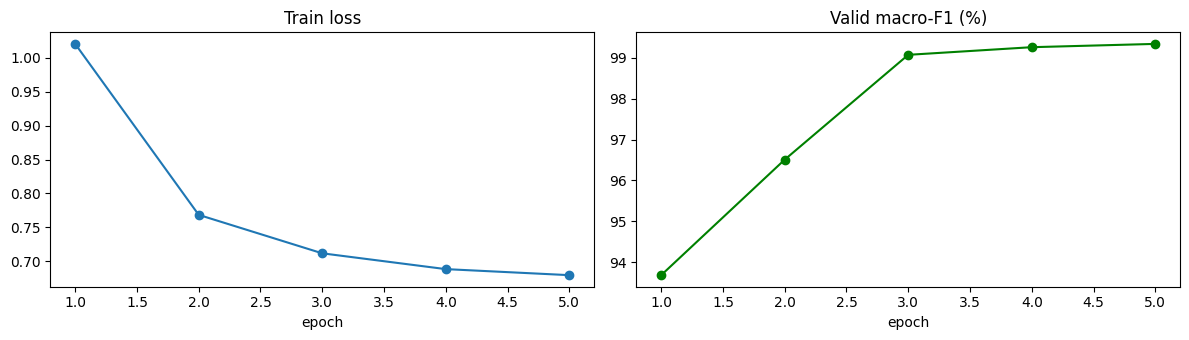

In [ ]:
model.load_state_dict(torch.load(CKPT, map_location=device)["model_state_dict"])   # lấy model tốt nhất
y_true, y_pred = predict(valid_loader)
print(f"Valid accuracy: {(y_true == y_pred).mean()*100:.2f}% | macro-F1: {f1_score(y_true, y_pred, average='macro')*100:.2f}%")

ep = [h["epoch"] for h in history]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.5))
a1.plot(ep, [h["train_loss"] for h in history], "o-"); a1.set_title("Train loss"); a1.set_xlabel("epoch")
a2.plot(ep, [h["val_macro_f1"] * 100 for h in history], "o-", color="green"); a2.set_title("Valid macro-F1 (%)"); a2.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(OUT_DIR / f"{RUN_NAME}_curves.png", dpi=120); plt.show()

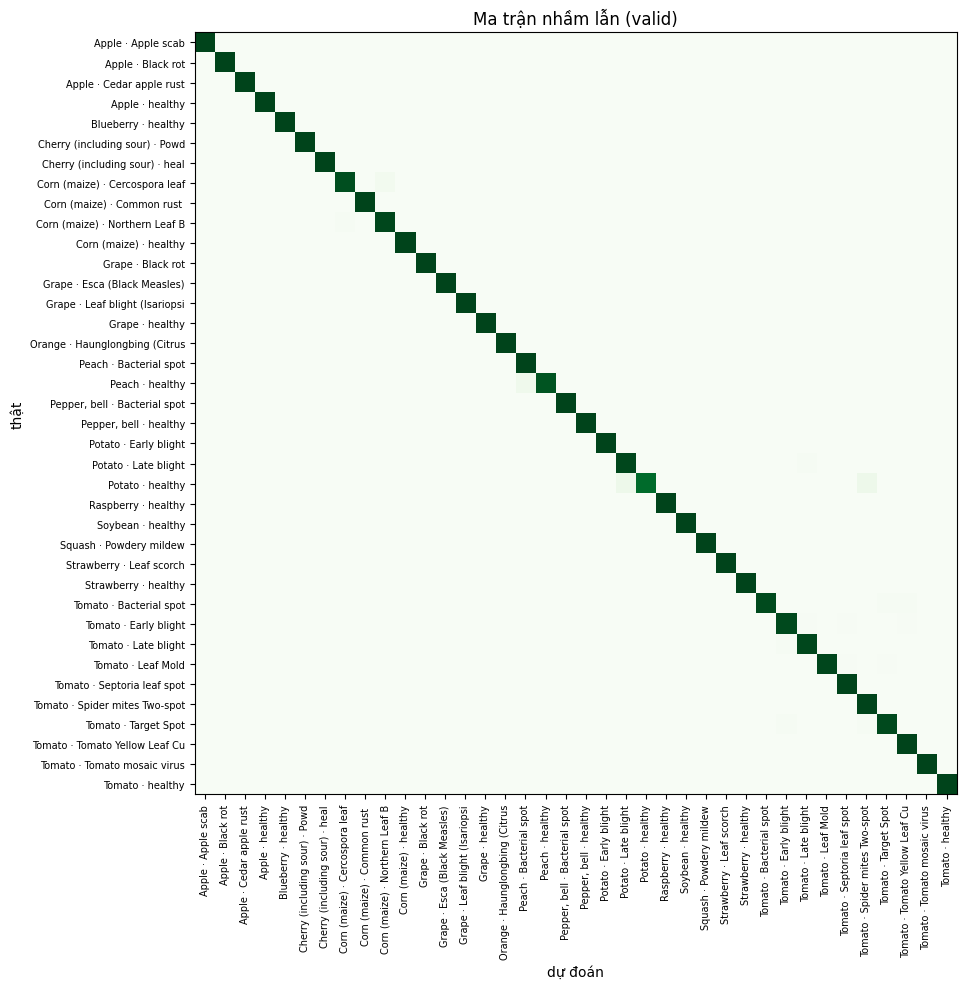

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES), normalize="true")
short = [c.replace("___", " · ").replace("_", " ")[:30] for c in CLASSES]
fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(cm, cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(short, rotation=90, fontsize=7)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(short, fontsize=7)
ax.set_xlabel("dự đoán"); ax.set_ylabel("thật"); ax.set_title("Ma trận nhầm lẫn (valid)")
plt.tight_layout(); plt.savefig(OUT_DIR / f"{RUN_NAME}_confusion_valid.png", dpi=120); plt.show()

## 7. CAM — model đang nhìn vào đâu?

Tầng cuối cho 512 "bản đồ đặc trưng" 7×7. Lấy tổng có trọng số (trọng số = hàng của lớp `fc` ứng với lớp được đoán)
→ một bản đồ 7×7 cho biết **vùng nào khiến model đoán lớp đó**. Đỏ = quan trọng. Model tốt phải "sáng" ở **vết bệnh**.

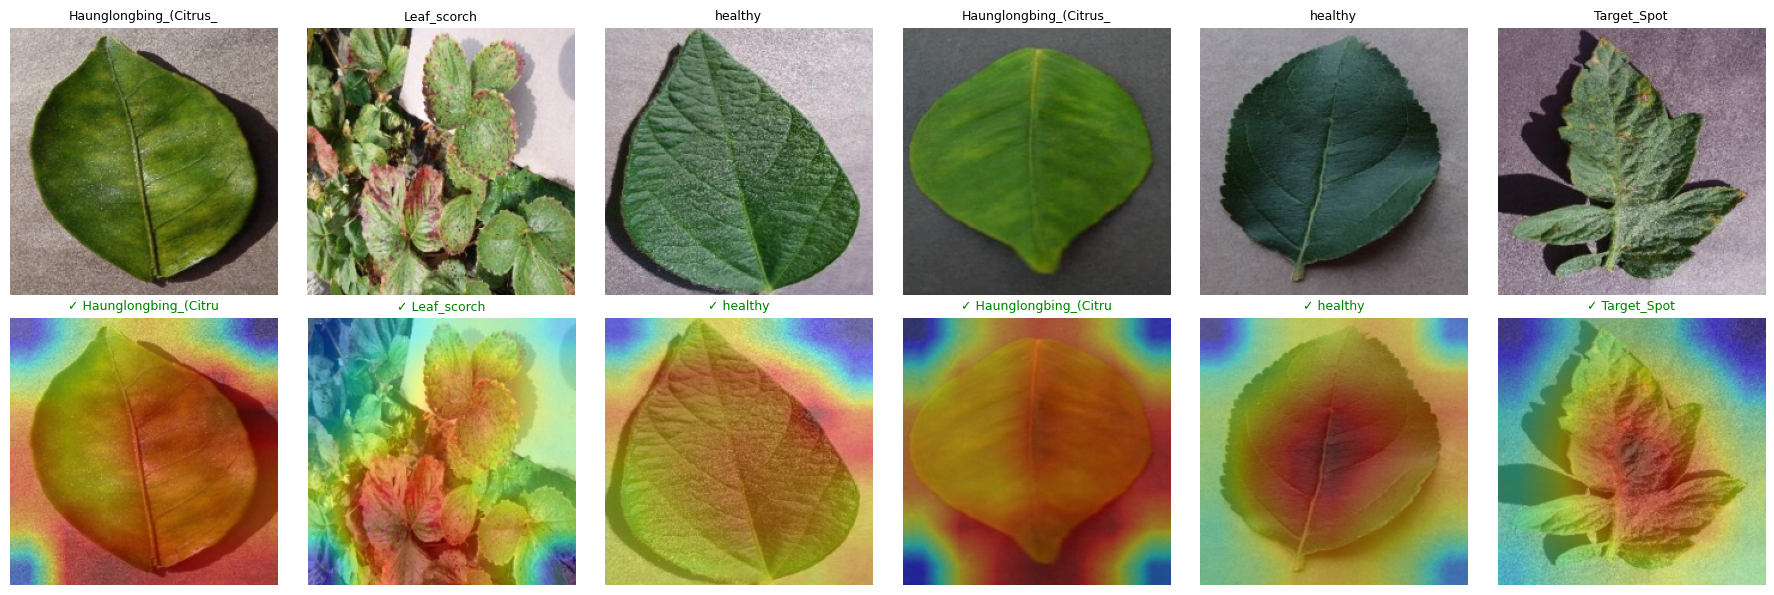

In [ ]:
feats = {}
hook = model.layer4.register_forward_hook(lambda m, i, o: feats.update(f=o))
W = model.fc.weight                                          # (38, 512)

model.eval()
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for k, i in enumerate(np.random.default_rng(0).choice(len(valid_ds), 6, replace=False)):
    x, y = valid_ds[int(i)]
    with torch.no_grad():
        c = model(x[None].to(device)).argmax(1).item()
        cam = torch.einsum("c,chw->hw", W[c], feats["f"][0])  # (7, 7)
        cam = nn.functional.interpolate(cam[None, None], size=IMAGE_SIZE, mode="bilinear")[0, 0]
        cam = ((cam - cam.min()) / (cam.max() - cam.min() + 1e-8)).cpu().numpy()
    axes[0, k].imshow(show(x)); axes[0, k].set_title(CLASSES[y].split("___")[1][:22], fontsize=9)
    axes[1, k].imshow(show(x)); axes[1, k].imshow(cam, cmap="jet", alpha=0.45)
    axes[1, k].set_title(("✓ " if c == y else "✗ ") + CLASSES[c].split("___")[1][:20], fontsize=9,
                         color="green" if c == y else "red")
    axes[0, k].axis("off"); axes[1, k].axis("off")
hook.remove()
plt.tight_layout(); plt.savefig(OUT_DIR / f"{RUN_NAME}_cam.png", dpi=110); plt.show()

## 8. Xuất ONNX cho backend

Backend đọc file `.onnx`. Kiểm tra: ONNX và PyTorch phải ra **cùng dự đoán**.

In [ ]:
try:
    import onnx, onnxruntime as ort
except ImportError:                      # Colab chưa có sẵn → cài
    !pip install -q onnx onnxruntime
    import onnx, onnxruntime as ort

ONNX_PATH = OUT_DIR / f"{RUN_NAME}.onnx"
model_cpu = copy.deepcopy(model).cpu().float().eval()
torch.onnx.export(model_cpu, torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE), str(ONNX_PATH),
                  input_names=["input"], output_names=["logits"], opset_version=17,
                  dynamic_axes={"input": {0: "batch_size"}, "logits": {0: "batch_size"}}, dynamo=False)

xb = torch.stack([valid_ds[i][0] for i in range(4)])
with torch.no_grad():
    ref = model_cpu(xb).numpy()
got = ort.InferenceSession(str(ONNX_PATH)).run(None, {"input": xb.numpy()})[0]
print(f"{ONNX_PATH.name}: {ONNX_PATH.stat().st_size/2**20:.1f} MB | cùng dự đoán: {(ref.argmax(1) == got.argmax(1)).all()}")

json.dump({"class_to_idx": {c: i for i, c in enumerate(CLASSES)},
           "idx_to_class": {str(i): c for i, c in enumerate(CLASSES)}},
          open(OUT_DIR / "class_indices.json", "w"), ensure_ascii=False, indent=2)

/tmp/ipykernel_542/1618480448.py:9: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model_cpu, torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE), str(ONNX_PATH),


resnet18_duy.onnx: 42.7 MB | cùng dự đoán: True


## 9. TEST — chấm **một lần duy nhất**

Chỉ đổi `RUN_FINAL_TEST = True` khi **đã chốt model**. Nếu nhìn điểm test rồi quay lại chỉnh tham số,
test thành "valid thứ hai" và mất ý nghĩa *điểm thật*.

In [ ]:
RUN_FINAL_TEST = False

if RUN_FINAL_TEST:
    test_ds = datasets.ImageFolder(DATA_DIR / "test", eval_tf)
    ty, tp = predict(DataLoader(test_ds, BATCH_SIZE, num_workers=NUM_WORKERS))
    result = {"accuracy": float((ty == tp).mean()), "macro_f1": float(f1_score(ty, tp, average="macro"))}
    json.dump(result, open(OUT_DIR / f"{RUN_NAME}_metrics_test.json", "w"), indent=2)
    print(result)